In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Employee Attrition Prediction Project")
print("Jupyter Notebook is working successfully!")

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)

Employee Attrition Prediction Project
Jupyter Notebook is working successfully!
Pandas version: 3.1.0
NumPy version: 2.5.4
Scikit-learn version: 1.9.1


In [2]:
from pathlib import Path

data_path = Path("../data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv")

print("Dataset exists:", data_path.exists())

if data_path.exists():
    print("Dataset location:", data_path.resolve())

Dataset exists: False


In [3]:
from pathlib import Path

print("Current notebook directory:")
print(Path.cwd())

print("\nFiles inside the data/raw folder:")

raw_folder = Path("../data/raw")

if raw_folder.exists():
    for file in raw_folder.iterdir():
        print(file.name)
else:
    print("The data/raw folder was not found at this relative path.")

print("\nFiles inside the project data folder:")

data_folder = Path("../data")

if data_folder.exists():
    for item in data_folder.iterdir():
        print(item.name)
else:
    print("The data folder was not found at this relative path.")

Current notebook directory:
c:\Users\prasa\employee-attrition-prediction-ml\notebooks

Files inside the data/raw folder:
WA_Fn-UseC_-HR-Employee-Attrition (1).csv

Files inside the project data folder:
raw


In [4]:
import pandas as pd
from pathlib import Path

data_path = Path("../data/raw/WA_Fn-UseC_-HR-Employee-Attrition (1).csv")

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (1470, 35)

First 5 rows:


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# 1. Data Understanding and Initial Inspection

The objective of this section is to understand the employee dataset, identify data-quality issues, and examine the distribution of employee attrition before building machine-learning models.


In [5]:
# Display all column names
print("Column Names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\nDataset Information:")
df.info()

Column Names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 n

In [6]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

# Check duplicate rows
print("\nNumber of Duplicate Rows:", df.duplicated().sum())

# Check total rows and columns
print("\nDataset Shape:", df.shape)

Missing Values:
Age                 0
Attrition           0
BusinessTravel      0
DailyRate           0
Department          0
DistanceFromHome    0
Education           0
EducationField      0
EmployeeCount       0
EmployeeNumber      0
dtype: int64

Number of Duplicate Rows: 0

Dataset Shape: (1470, 35)


Attrition Counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition Percentages:
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


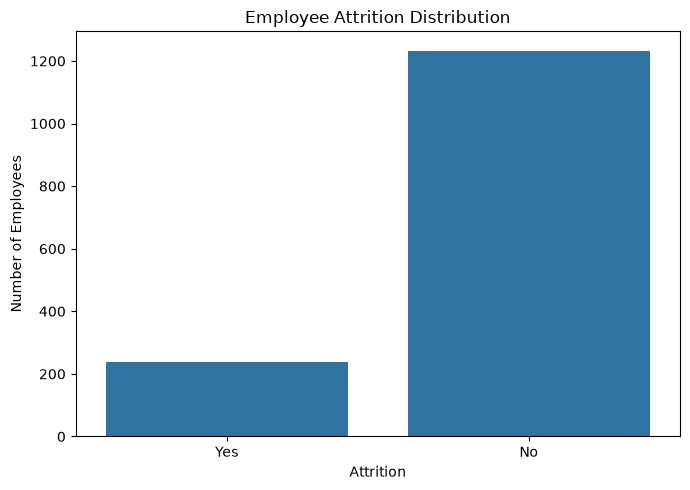

In [7]:
# Count employees who left and stayed
print("Attrition Counts:")
print(df["Attrition"].value_counts())

# Calculate percentages
print("\nAttrition Percentages:")
print((df["Attrition"].value_counts(normalize=True) * 100).round(2))

# Visualize the distribution
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Attrition")

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

# 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us identify patterns, relationships, and trends in the employee dataset before building machine-learning models.

In this section, we will examine employee attrition in relation to overtime, job satisfaction, and age.



Attrition Percentage by Overtime Status:


Attrition,No,Yes
OverTime,,
No,89.56,10.44
Yes,69.47,30.53


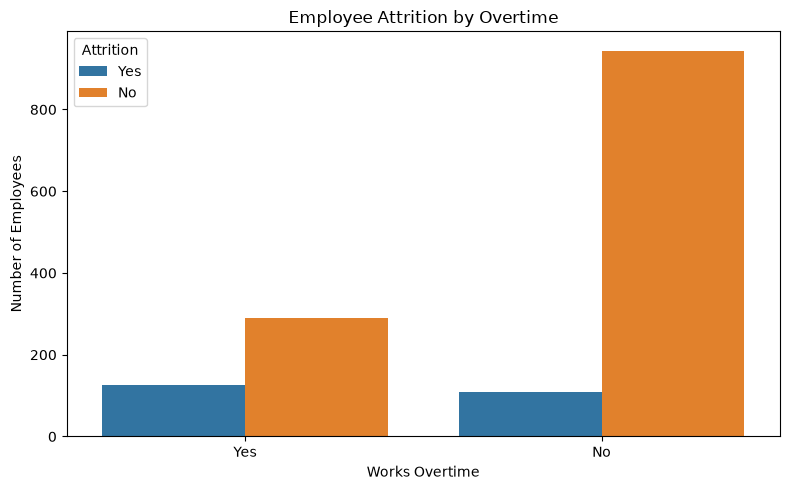

In [8]:
# Calculate attrition percentage by overtime status

overtime_attrition = pd.crosstab(
    df["OverTime"],
    df["Attrition"],
    normalize="index"
) * 100

print("Attrition Percentage by Overtime Status:")
display(overtime_attrition.round(2))

# Visualize the relationship

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="OverTime",
    hue="Attrition"
)

plt.title("Employee Attrition by Overtime")
plt.xlabel("Works Overtime")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

Attrition Percentage by Job Satisfaction:


Attrition,No,Yes
JobSatisfaction,,
1,77.16,22.84
2,83.57,16.43
3,83.48,16.52
4,88.67,11.33


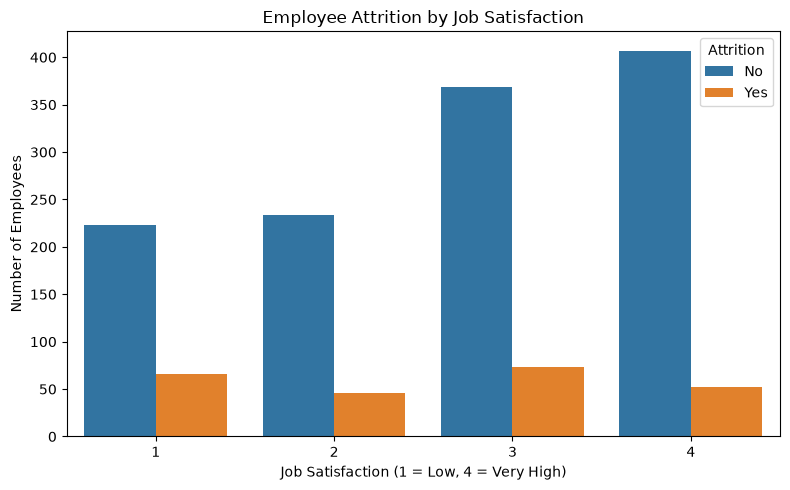

In [9]:
# Calculate attrition percentage by job satisfaction

satisfaction_attrition = pd.crosstab(
    df["JobSatisfaction"],
    df["Attrition"],
    normalize="index"
) * 100

print("Attrition Percentage by Job Satisfaction:")
display(satisfaction_attrition.round(2))

# Visualize the relationship

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="JobSatisfaction",
    hue="Attrition"
)

plt.title("Employee Attrition by Job Satisfaction")
plt.xlabel("Job Satisfaction (1 = Low, 4 = Very High)")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

Attrition Percentage by Age Group:


Attrition,No,Yes
AgeGroup,,
18-25,64.23,35.77
26-35,80.86,19.14
36-45,90.81,9.19
46-55,88.50,11.50
56-65,82.98,17.02


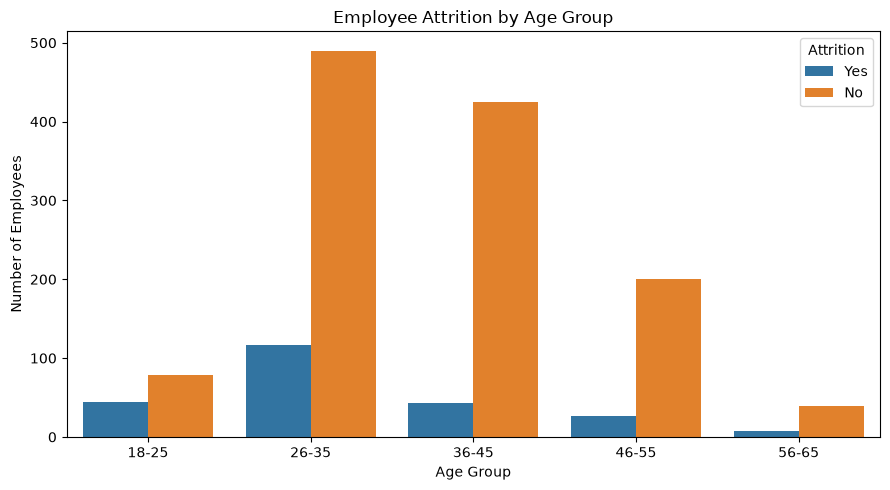

In [10]:
# Create age groups

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65"]
)

# Calculate attrition percentage by age group

age_attrition = pd.crosstab(
    df["AgeGroup"],
    df["Attrition"],
    normalize="index"
) * 100

print("Attrition Percentage by Age Group:")
display(age_attrition.round(2))

# Visualize the relationship

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="AgeGroup",
    hue="Attrition"
)

plt.title("Employee Attrition by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

# 3. Data Preparation and Baseline Model

In this section, we will prepare the employee dataset for machine learning. We will separate the target variable, split the data into training and testing sets, and build a preprocessing pipeline for numerical and categorical features.

Our first model will be Logistic Regression, which will serve as a baseline for comparison with more advanced models.



In [11]:
# Import required libraries

import pandas as pd

from sklearn.model_selection import train_test_split

# Create a copy of the original dataset
ml_df = df.copy()

# Remove the AgeGroup column created during EDA
# because it is derived from Age
ml_df = ml_df.drop(columns=["AgeGroup"], errors="ignore")

# Remove columns that have no useful predictive information
# in this dataset
columns_to_drop = [
    "EmployeeCount",
    "EmployeeNumber",
    "Over18",
    "StandardHours"
]

ml_df = ml_df.drop(columns=columns_to_drop)

# Separate features and target
X = ml_df.drop(columns=["Attrition"])
y = ml_df["Attrition"].map({"No": 0, "Yes": 1})

# Check the results
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nMissing target values:", y.isna().sum())

print("\nCategorical features:")
print(X.select_dtypes(include=["object", "str"]).columns.tolist())

print("\nNumerical features:")
print(X.select_dtypes(include=["number"]).columns.tolist())

Feature matrix shape: (1470, 30)
Target shape: (1470,)

Target distribution:
Attrition
0    1233
1     237
Name: count, dtype: int64

Missing target values: 0

Categorical features:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Numerical features:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [12]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training features: (1176, 30)
Testing features: (294, 30)

Training target distribution:
Attrition
0    83.84
1    16.16
Name: proportion, dtype: float64

Testing target distribution:
Attrition
0    84.01
1    15.99
Name: proportion, dtype: float64


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Identify categorical and numerical columns

categorical_features = X.select_dtypes(
include=["object", "str"]
).columns.tolist()

numerical_features = X.select_dtypes(
include=["number"]
).columns.tolist()

# Preprocess categorical features

categorical_transformer = OneHotEncoder(
handle_unknown="ignore"
)

# Preprocess numerical features

numerical_transformer = StandardScaler()

# Combine both preprocessing steps

preprocessor = ColumnTransformer(
transformers=[
("categorical", categorical_transformer, categorical_features),
("numerical", numerical_transformer, numerical_features)
]
)

# Create the complete machine learning pipeline

logistic_model = Pipeline(
steps=[
("preprocessor", preprocessor),
("classifier", LogisticRegression(
max_iter=2000,
class_weight="balanced",
random_state=42
))
]
)

print("Preprocessing pipeline created successfully!")
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))


Preprocessing pipeline created successfully!
Categorical features: 7
Numerical features: 23


In [14]:
# Train the Logistic Regression pipeline

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [15]:
# Predict attrition on the test dataset

y_pred = logistic_model.predict(X_test)

# Calculate probabilities of attrition
y_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10].tolist())

print("\nFirst 10 predicted attrition probabilities:")
print(y_prob[:10].round(3).tolist())

Predictions generated successfully!

First 10 actual values:
[0, 0, 0, 0, 1, 0, 0, 0, 0, 0]

First 10 predicted values:
[0, 0, 0, 0, 1, 1, 0, 0, 0, 0]

First 10 predicted attrition probabilities:
[0.287, 0.022, 0.408, 0.04, 0.674, 0.642, 0.081, 0.15, 0.021, 0.238]


In [16]:
from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
roc_auc_score,
classification_report
)

# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test, y_prob)

# Display results

print("LOGISTIC REGRESSION - MODEL EVALUATION")
print("-" * 45)

print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nDetailed Classification Report:")
print(
classification_report(
y_test,
y_pred,
target_names=["Stayed", "Left"],
zero_division=0
)
)


LOGISTIC REGRESSION - MODEL EVALUATION
---------------------------------------------
Accuracy : 0.7517 (75.17%)
Precision: 0.3488
Recall   : 0.6383
F1-score : 0.4511
ROC-AUC  : 0.8032

Detailed Classification Report:
              precision    recall  f1-score   support

      Stayed       0.92      0.77      0.84       247
        Left       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



Confusion Matrix:
[[191  56]
 [ 17  30]]


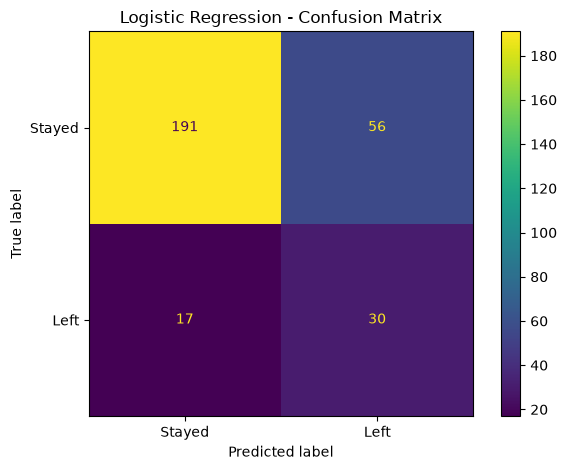

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize the confusion matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Left"]
)

display_matrix.plot(values_format="d")

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
# Count actual and predicted attrition cases

print("Actual attrition cases in test data:", int(y_test.sum()))
print("Predicted attrition cases:", int(y_pred.sum()))

print(
    "Correctly identified attrition cases:",
    int(((y_test == 1) & (y_pred == 1)).sum())
)

print(
    "Missed attrition cases:",
    int(((y_test == 1) & (y_pred == 0)).sum())
)

Actual attrition cases in test data: 47
Predicted attrition cases: 86
Correctly identified attrition cases: 30
Missed attrition cases: 17


In [19]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Preprocess categorical and numerical features
rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Create the Random Forest pipeline
rf_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [20]:
# Train the Random Forest model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [21]:
# Generate predictions
rf_pred = rf_model.predict(X_test)

# Generate probabilities for the attrition class
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated successfully!")

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted values:")
print(rf_pred[:10].tolist())

print("\nFirst 10 predicted attrition probabilities:")
print(rf_prob[:10].round(3).tolist())

Random Forest predictions generated successfully!

First 10 actual values:
[0, 0, 0, 0, 1, 0, 0, 0, 0, 0]

First 10 predicted values:
[1, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 predicted attrition probabilities:
[0.706, 0.142, 0.259, 0.049, 0.469, 0.276, 0.212, 0.142, 0.043, 0.61]


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

print("RANDOM FOREST - MODEL EVALUATION")
print("-" * 45)

print(f"Accuracy : {accuracy_score(y_test, rf_pred):.4f}")
print(
    f"Precision: "
    f"{precision_score(y_test, rf_pred, zero_division=0):.4f}"
)
print(
    f"Recall   : "
    f"{recall_score(y_test, rf_pred, zero_division=0):.4f}"
)
print(f"F1-score : {f1_score(y_test, rf_pred, zero_division=0):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, rf_prob):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=["Stayed", "Left"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

RANDOM FOREST - MODEL EVALUATION
---------------------------------------------
Accuracy : 0.8265
Precision: 0.4545
Recall   : 0.4255
F1-score : 0.4396
ROC-AUC  : 0.7898

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.89      0.90      0.90       247
        Left       0.45      0.43      0.44        47

    accuracy                           0.83       294
   macro avg       0.67      0.66      0.67       294
weighted avg       0.82      0.83      0.82       294


Confusion Matrix:
[[223  24]
 [ 27  20]]


In [23]:
# Check the features used by the models

print("Target column:", "Attrition")
print("Target included in X:", "Attrition" in X.columns)

print("\nIdentifier columns still present:")
print([
    col for col in X.columns
    if "id" in col.lower()
    or "number" in col.lower()
])

print("\nTraining and testing overlap:")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training index overlap with testing:",
      len(set(X_train.index) & set(X_test.index)))

print("\nMissing values in training features:", X_train.isna().sum().sum())
print("Missing values in testing features:", X_test.isna().sum().sum())

Target column: Attrition
Target included in X: False

Identifier columns still present:
[]

Training and testing overlap:
Training rows: 1176
Testing rows: 294
Training index overlap with testing: 0

Missing values in training features: 0
Missing values in testing features: 0


In [24]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate both existing pipelines on training data only
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

lr_cv = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Summarize cross-validation results
cv_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Logistic Regression": [
        lr_cv["test_accuracy"].mean(),
        lr_cv["test_precision"].mean(),
        lr_cv["test_recall"].mean(),
        lr_cv["test_f1"].mean(),
        lr_cv["test_roc_auc"].mean()
    ],
    "Random Forest": [
        rf_cv["test_accuracy"].mean(),
        rf_cv["test_precision"].mean(),
        rf_cv["test_recall"].mean(),
        rf_cv["test_f1"].mean(),
        rf_cv["test_roc_auc"].mean()
    ]
})

print("Five-Fold Cross-Validation Results")
display(cv_results.round(4))

Five-Fold Cross-Validation Results


,Metric,Logistic Regression,Random Forest
0,Accuracy,0.7534,0.8512
1,Precision,0.3721,0.5602
2,Recall,0.7368,0.4158
3,F1-score,0.4925,0.4693
4,ROC-AUC,0.8273,0.8059


In [25]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Create a fresh Logistic Regression pipeline
tuned_lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Parameters to compare
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": ["balanced", None]
}

# Five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Optimize F1-score using training data only
grid_search = GridSearchCV(
    estimator=tuned_lr_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Fit using training data only
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest mean cross-validation F1-score:")
print(round(grid_search.best_score_, 4))

Best parameters:
{'classifier__C': 1, 'classifier__class_weight': None}

Best mean cross-validation F1-score:
0.561


In [26]:
from sklearn.model_selection import cross_validate

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Evaluate the tuned model using training data only
tuned_cv_results = cross_validate(
    grid_search.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Display mean cross-validation metrics
tuned_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Tuned Logistic Regression": [
        tuned_cv_results["test_accuracy"].mean(),
        tuned_cv_results["test_precision"].mean(),
        tuned_cv_results["test_recall"].mean(),
        tuned_cv_results["test_f1"].mean(),
        tuned_cv_results["test_roc_auc"].mean()
    ]
})

print("Tuned Logistic Regression — 5-Fold Cross-Validation")
display(tuned_metrics.round(4))

Tuned Logistic Regression — 5-Fold Cross-Validation


,Metric,Tuned Logistic Regression
0,Accuracy,0.8903
1,Precision,0.7763
2,Recall,0.4421
3,F1-score,0.5610
4,ROC-AUC,0.8392


In [27]:
from sklearn.model_selection import GridSearchCV

recall_search = GridSearchCV(
    estimator=tuned_lr_pipeline,
    param_grid={
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__class_weight": ["balanced", None]
    },
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Train and tune using training data only
recall_search.fit(X_train, y_train)

print("Best parameters for recall:")
print(recall_search.best_params_)

print("\nBest mean cross-validation recall:")
print(round(recall_search.best_score_, 4))

Best parameters for recall:
{'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}

Best mean cross-validation recall:
0.7579


In [28]:
# Evaluate the recall-focused Logistic Regression model

recall_cv_results = cross_validate(
    recall_search.best_estimator_,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

recall_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "F1-focused Model": [
        tuned_cv_results["test_accuracy"].mean(),
        tuned_cv_results["test_precision"].mean(),
        tuned_cv_results["test_recall"].mean(),
        tuned_cv_results["test_f1"].mean(),
        tuned_cv_results["test_roc_auc"].mean()
    ],
    "Recall-focused Model": [
        recall_cv_results["test_accuracy"].mean(),
        recall_cv_results["test_precision"].mean(),
        recall_cv_results["test_recall"].mean(),
        recall_cv_results["test_f1"].mean(),
        recall_cv_results["test_roc_auc"].mean()
    ]
})

print("Comparison of Tuned Logistic Regression Models")
display(recall_metrics.round(4))

Comparison of Tuned Logistic Regression Models


,Metric,F1-focused Model,Recall-focused Model
0,Accuracy,0.8903,0.7483
1,Precision,0.7763,0.3684
2,Recall,0.4421,0.7579
3,F1-score,0.5610,0.4947
4,ROC-AUC,0.8392,0.8242


In [29]:
from pathlib import Path
import joblib

# Define the model output directory
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the selected F1-focused model
model_path = model_dir / "employee_attrition_logistic_regression.joblib"

joblib.dump(grid_search.best_estimator_, model_path)

print("Model saved successfully!")
print("Saved location:", model_path.resolve())
print("Selected parameters:", grid_search.best_params_)

Model saved successfully!
Saved location: C:\Users\prasa\employee-attrition-prediction-ml\models\employee_attrition_logistic_regression.joblib
Selected parameters: {'classifier__C': 1, 'classifier__class_weight': None}


In [30]:
from pathlib import Path
import joblib
import pandas as pd

# Locate the saved model
model_path = Path("../models/employee_attrition_logistic_regression.joblib")

# Load the saved model
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(loaded_model).__name__)

# Select five rows from the test features
sample_employees = X_test.head(5).copy()

# Generate predictions
sample_predictions = loaded_model.predict(sample_employees)
sample_probabilities = loaded_model.predict_proba(sample_employees)[:, 1]

# Display results
verification_results = pd.DataFrame({
    "Actual Attrition": y_test.loc[sample_employees.index].map({
        0: "No",
        1: "Yes"
    }),
    "Predicted Attrition": pd.Series(
        sample_predictions,
        index=sample_employees.index
    ).map({
        0: "No",
        1: "Yes"
    }),
    "Probability of Attrition (%)": (
        sample_probabilities * 100
    ).round(2)
})

display(verification_results)

Model loaded successfully!
Model type: Pipeline


,Actual Attrition,Predicted Attrition,Probability of Attrition (%)
1061,No,No,7.71
891,No,No,0.28
456,No,No,16.47
922,No,No,0.51
69,Yes,No,31.59


Final Test-Set Evaluation


,Metric,Score
0,Accuracy,0.8605
1,Precision,0.6154
2,Recall,0.3404
3,F1-score,0.4384
4,ROC-AUC,0.8115



Classification Report:
              precision    recall  f1-score   support

 Stayed (No)       0.88      0.96      0.92       247
  Left (Yes)       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294



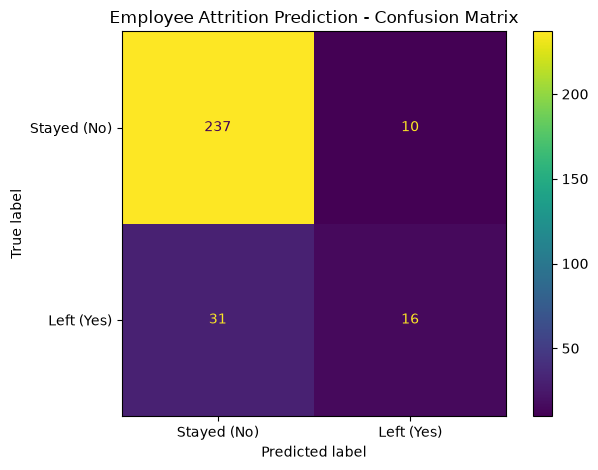

In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Generate predictions on the full test set
final_predictions = loaded_model.predict(X_test)
final_probabilities = loaded_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, final_predictions),
        precision_score(y_test, final_predictions, zero_division=0),
        recall_score(y_test, final_predictions, zero_division=0),
        f1_score(y_test, final_predictions, zero_division=0),
        roc_auc_score(y_test, final_probabilities)
    ]
})

print("Final Test-Set Evaluation")
display(final_metrics.round(4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_predictions,
    target_names=["Stayed (No)", "Left (Yes)"],
    zero_division=0
))

# Plot the confusion matrix
cm = confusion_matrix(y_test, final_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed (No)", "Left (Yes)"]
)

disp.plot()
plt.title("Employee Attrition Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

In [32]:
cm = confusion_matrix(y_test, final_predictions)

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nDetailed Results:")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Confusion Matrix:
[[237  10]
 [ 31  16]]

Detailed Results:
True Negatives: 237
False Positives: 10
False Negatives: 31
True Positives: 16


In [33]:
import pandas as pd

# Access the trained preprocessing and classifier steps
preprocessor_fitted = loaded_model.named_steps["preprocessor"]
classifier_fitted = loaded_model.named_steps["classifier"]

# Get the names of features after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Extract Logistic Regression coefficients
coefficients = classifier_fitted.coef_[0]

# Create a table of feature coefficients
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Rank features by coefficient magnitude
coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

print("Top 15 Features by Absolute Logistic Regression Coefficient")
display(
    coefficient_df[
        ["Feature", "Coefficient"]
    ].head(15).round(4)
)

Top 15 Features by Absolute Logistic Regression Coefficient


,Feature,Coefficient
19,categorical__JobRole_Research Director,-1.0341
16,categorical__JobRole_Laboratory Technician,1.0303
26,categorical__OverTime_No,-0.9288
0,categorical__BusinessTravel_Non-Travel,-0.9164
27,categorical__OverTime_Yes,0.9161
1,categorical__BusinessTravel_Travel_Frequently,0.8981
22,categorical__JobRole_Sales Representative,0.8803
10,categorical__EducationField_Other,-0.7151
6,categorical__EducationField_Human Resources,0.5997
14,categorical__JobRole_Healthcare Representative,-0.5793


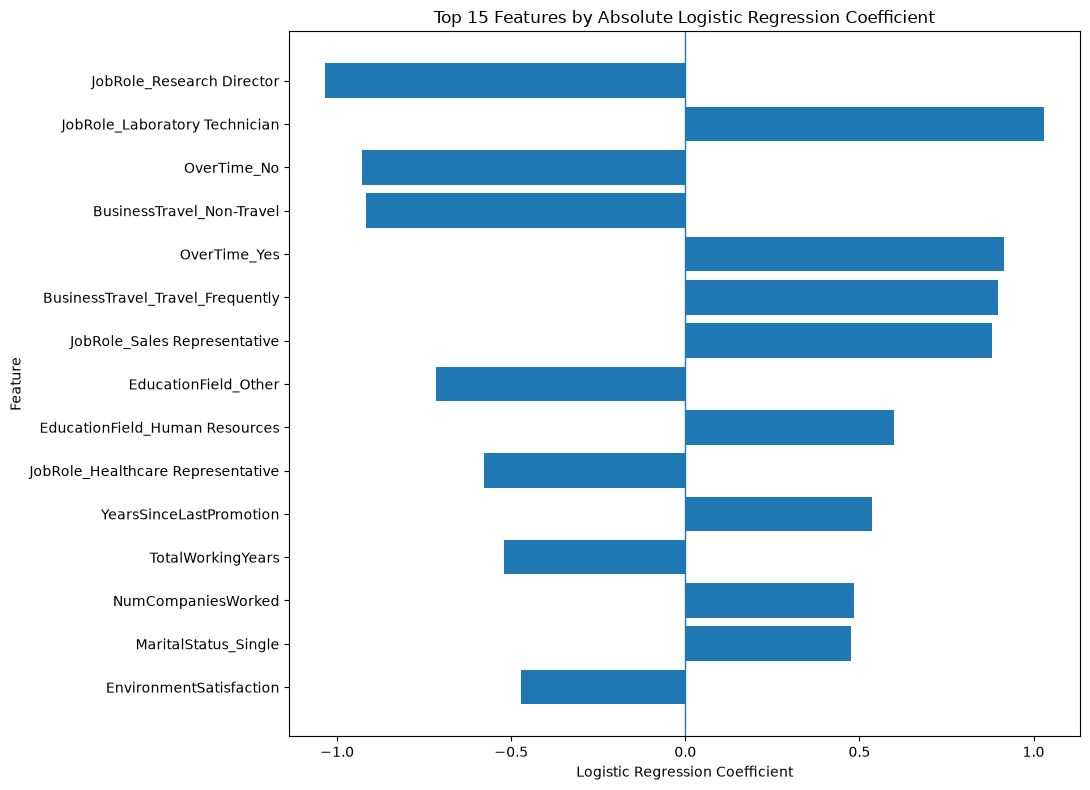

Chart saved successfully:
C:\Users\prasa\employee-attrition-prediction-ml\reports\figures\logistic_regression_coefficients.png


In [34]:
import matplotlib.pyplot as plt
from pathlib import Path

# Select the top 15 features by absolute coefficient
top_features = coefficient_df.head(15).copy()

# Shorten feature names for readability
top_features["Display_Feature"] = (
    top_features["Feature"]
    .str.replace("categorical__", "", regex=False)
    .str.replace("numerical__", "", regex=False)
)

# Reverse order so the largest absolute coefficient appears at the top
top_features = top_features.sort_values(
    by="Coefficient",
    key=abs,
    ascending=True
)

# Create the chart
plt.figure(figsize=(11, 8))

plt.barh(
    top_features["Display_Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, linewidth=1)
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Features by Absolute Logistic Regression Coefficient")
plt.tight_layout()

# Save the chart
figure_dir = Path("../reports/figures")
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = figure_dir / "logistic_regression_coefficients.png"

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully:")
print(figure_path.resolve())